In [21]:
try:
    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt
    import zhplot
    import statsmodels.api as sm
except ValueError:
    print("请先安装库")  

In [24]:
path = "D:/OneDrive - m.gduf.edu.cn/工作杂项/stata/课程的代码演示/2026自相关"
autoacc_df = pd.read_stata(path+"/consumption_china.dta",index_col="year")
autoacc_df.head()

,c,y,c_ratio
year,,,
1978,184,381,0.482940
1979,208,419,0.496420
1980,238,463,0.514039
1981,264,492,0.536585
1982,288,528,0.545455


In [25]:
# 添加常数项
c = sm.add_constant(autoacc_df['c'])
model = sm.OLS(autoacc_df['y'],c).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.989
Model:                            OLS   Adj. R-squared:                  0.989
Method:                 Least Squares   F-statistic:                     2442.
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           5.13e-28
Time:                        16:30:39   Log-Likelihood:                -219.57
No. Observations:                  29   AIC:                             443.1
Df Residuals:                      27   BIC:                             445.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -419.0076    135.525     -3.092      0.0

## 残差图

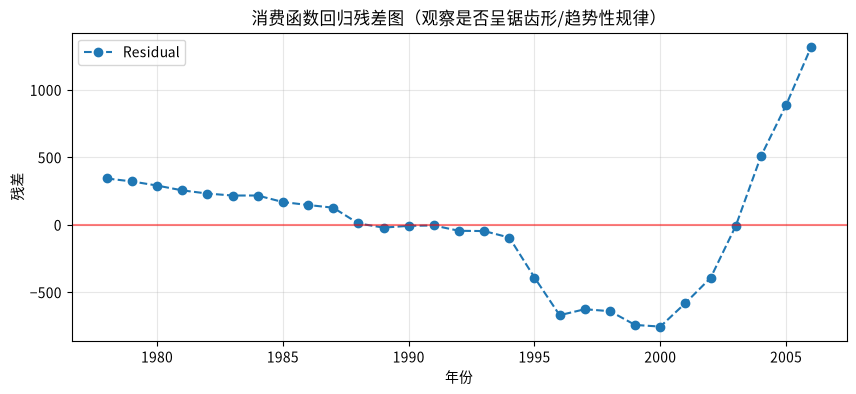

In [27]:
plt.figure(figsize=(10, 4))
plt.plot(autoacc_df.index, model.resid, marker='o', linestyle='--', label='Residual')
plt.axhline(y=0, color='red', linestyle='-', alpha=0.5)   # 0刻度参考线
plt.xlabel('年份'); plt.ylabel('残差') 
plt.title('消费函数回归残差图（观察是否呈锯齿形/趋势性规律）')
plt.grid(alpha=0.3); plt.legend(); plt.show()

In [ ]:
# ============================================================
# 三、DW检验（Durbin-Watson）：只能检验一阶自相关
# ============================================================
from statsmodels.stats.stattools import durbin_watson

def dw_test(model, dL, dU):
    # DW统计量 ≈ 2(1-ρ)，越接近2说明一阶自相关越弱
    # dL、dU需要对照教材DW临界值表手动填入，与下面三要素有关：
    #   1) 显著性水平：一般查5%
    #   2) 样本量 n：本次约为 len(df)（年份数）
    #   3) 解释变量个数 k'：k'=1（只含收入y，不含常数项）
    dwstat = durbin_watson(model.resid)   # 计算DW统计量
    print(f"DW检验统计量: {dwstat:.4f}")
    # 分五区判断：小于dL→正相关；dL~dU→不确定；dU~4-dU→无自相关；4-dU~4-dL→不确定；>4-dL→负相关
    if dwstat < dL:
        result = "存在正自相关。"
    elif dwstat > 4 - dL:
        result = "存在负自相关。"
    elif dL <= dwstat <= dU or (4-dU) <= dwstat <= (4-dL):
        result = "落入不确定区，DW检验无法判定，需结合BG检验。"
    else:
        result = "未发现一阶自相关。"
    print(f"结论：{result}")

# ============================================================
# 查表三步走（以本模型为例）
# 第1步 定显著性水平：本练习取5%（若不放心可同时看1%那一页）
# 第2步 定行：样本量 n=29（看回归摘要 No. Observations: 29）
# 第3步 定列：解释变量个数 k'=1（模型只有c一个解释变量, 不含常数项）
# 5%的DW表k'=1列摘录: n=25时 dL=1.288 dU=1.454; n=30时 dL=1.352 dU=1.489
# n=29在表中未直接列出, 教材惯例取最接近的一行 n=30 -> dL=1.352, dU=1.489
# 判断: DW=0.1586 < dL=1.352, 落在①区 -> 存在正自相关
# ============================================================
dw_test(model, dL=1.352, dU=1.489)  

DW检验统计量: 0.1586
结论：存在正自相关。


In [32]:
# ============================================================
# 四、BG/LM检验（Breusch-Godfrey）：可检验任意阶自相关，结论更可靠
# ============================================================
from statsmodels.stats.diagnostic import acorr_breusch_godfrey

def bg_test(model, nlags=2):
    # nlags为检验的滞后阶数（如残差对滞后1期、2期...的自相关）; 原假设H0：无自相关
    # 原理：把OLS残差对“原解释变量+残差的滞后1~nlags期”再做辅助回归,
    #       用辅助回归的R²算LM统计量: LM = n*R² ~ 卡方(nlags)
    # 优点：a) 能检验任意高阶自相关（DW只能看一阶）; b) 无“不确定区”; c) 含滞后因变量也能用
    # 怎么看：直接看p值, 不需要查表！（这是BG检验比DW最省事的地方）
    bg = acorr_breusch_godfrey(model, nlags=nlags)
    # 返回( LM检验统计量, 对应p值, F统计量, F检验的p值 )
    # 一般情况下只需前两个：[0]是卡方统计量, [1]是它的p值, p值<0.05就拒绝H0
    lm_stat, lm_p, f_stat, f_p = bg[0], bg[1], bg[2], bg[3]
    print(f"BG检验: 滞后阶数={nlags}")
    print(f"LM检验统计量={lm_stat:.4f}, p值={lm_p:.4f}")
    # 本例结果LM=26.9523, p值≈1.4e-06（打印显示0.0000是被截断, 实际极小）
    if lm_p < 0.05:
        print("p值 < 0.05，拒绝原假设：存在自相关。")
    else:
        print("p值 >= 0.05，不能拒绝原假设：自相关性不显著。")
    return lm_p

# 调用BG检验：nlags=2表示同时检查残差的1阶、2阶滞后自相关
# 本例p值≈1.4e-06 < 0.05 -> 与DW检验结论一致: 存在自相关
bg_test(model, nlags=2)

BG检验: 滞后阶数=2
LM检验统计量=26.9523, p值=0.0000
p值 < 0.05，拒绝原假设：存在自相关。


np.float64(1.4040229868241247e-06)